In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

from collections import Counter

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix,accuracy_score,roc_curve,classification_report,f1_score

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
# from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
import lightgbm as lgb
# from mlxtend.classifier import StackingCVClassifier
import warnings
warnings.filterwarnings('ignore')

In [2]:
data = pd.read_csv('diabetes.csv')

In [3]:
X = data.drop(['Diabetes'],axis = 1)
y = data['Diabetes']

from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(X, y ,test_size= 0.2, random_state= 42)

In [4]:
model = lgb.LGBMClassifier(verbose=-1)

model.fit(x_train, y_train)

lgb_pred = model.predict(x_test)
f1 = f1_score(y_test, lgb_pred)
f1

0.8878923766816144

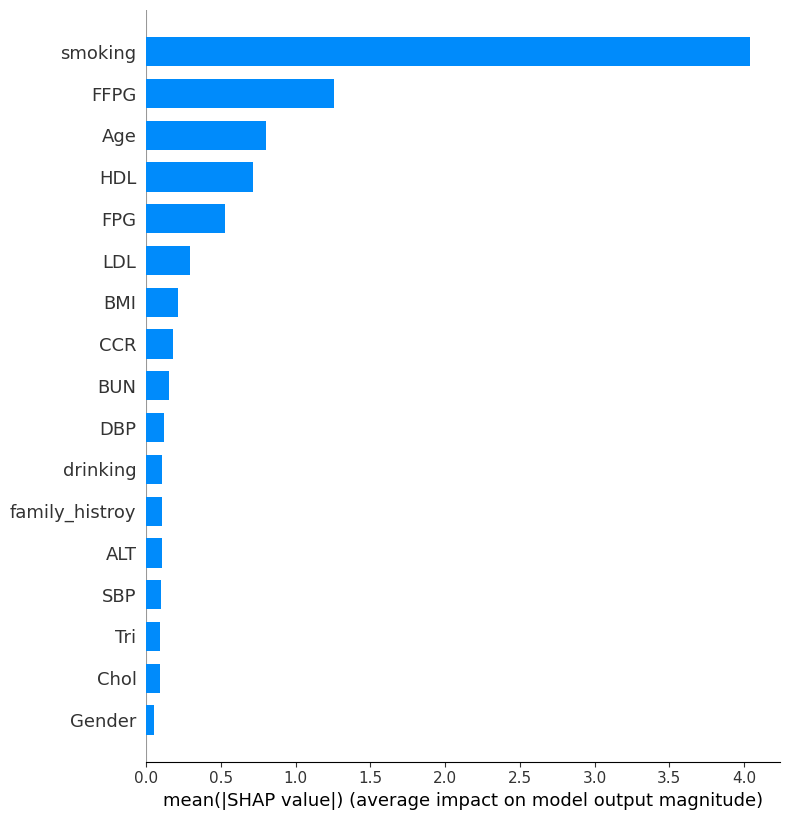

In [5]:
import time
s = time.time()
import shap
explainer = shap.Explainer(model)
shap_values = explainer.shap_values(x_test)

# Visualize SHAP values
shap.summary_plot(shap_values, x_test, plot_type="bar")

In [6]:
e = time.time()
e-s

0.5377888679504395

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# Assuming you have already calculated shap_values

# Generate the summary plot with bar chart
# shap.summary_plot(shap_values, x_test, plot_type="bar", show=False, color='c')

# Extract and display the SHAP values for each feature
shap_df = pd.DataFrame(shap_values, columns=x_test.columns)
shap_values_per_feature = shap_df.abs().mean()  # Calculate the average absolute SHAP value per feature

# Sort SHAP values from largest to smallest
shap_values_per_feature_sorted = shap_values_per_feature.sort_values(ascending=True)

In [7]:
shap_values_per_feature_sorted


Gender            0.050789
Chol              0.092217
Tri               0.094167
SBP               0.101140
ALT               0.103118
family_histroy    0.103132
drinking          0.105230
DBP               0.116074
BUN               0.149788
CCR               0.176956
BMI               0.214328
LDL               0.295142
FPG               0.529391
HDL               0.713931
Age               0.801038
FFPG              1.254520
smoking           4.039053
dtype: float64

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import shap

# Assuming you have already calculated shap_values and x_test

# Generate the summary plot with bar chart
# shap.summary_plot(shap_values, x_test, plot_type="bar", show=False, color='c')

# Extract and display the SHAP values for each feature
shap_df = pd.DataFrame(shap_values, columns=x_test.columns)
shap_values_per_feature = shap_df.abs().mean()  # Calculate the average absolute SHAP value per feature

# Sort SHAP values from largest to smallest
shap_values_per_feature_sorted = shap_values_per_feature.sort_values(ascending=True)

# 最小-最大归一化到 [0, 1] 之间
shap_values_per_feature_normalized = (shap_values_per_feature - shap_values_per_feature.min()) / (shap_values_per_feature.max() - shap_values_per_feature.min())
shap_values_per_feature_normalized = shap_values_per_feature_normalized.sort_values(ascending=True)
shap_values_per_feature_normalized

Gender            0.000000
Chol              0.010387
Tri               0.010876
SBP               0.012625
ALT               0.013121
family_histroy    0.013124
drinking          0.013650
DBP               0.016369
BUN               0.024823
CCR               0.031635
BMI               0.041005
LDL               0.061268
FPG               0.120003
HDL               0.166273
Age               0.188114
FFPG              0.301818
smoking           1.000000
dtype: float64

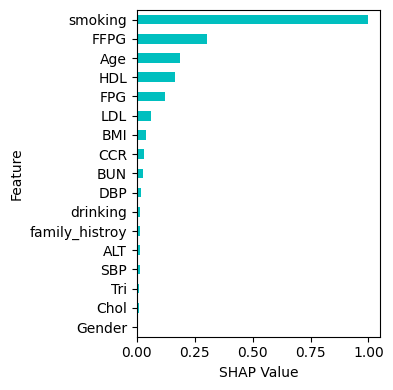

In [9]:
# Create a vertical figure for better spacing
plt.figure(figsize=(4, 4))
# colors = plt.cm.viridis(range(len(sorted_feature_importance_df)))

# colors = plt.color_palette("c", len(shap_values_per_feature_sorted))

# Plot the sorted SHAP values for each feature vertically
bar_plot = shap_values_per_feature_normalized.plot(kind='barh', color='c')
# plt.title('SHAP Values for H1N1 Vaccine Features', fontsize=14)
plt.xlabel('SHAP Value')
plt.ylabel('Feature')

# # Annotate the bars with SHAP values
# for i, value in enumerate(shap_values_per_feature_sorted):
#     bar_plot.text(value + 0.01, i, f'{value:.4f}', ha='left', va='center', fontsize=8)

plt.tight_layout()  # Adjusts subplot parameters to give specified padding

plt.savefig('shap_diabetes_lgb_normalized.eps', format='eps', dpi=300)

plt.show()

In [7]:
import time
s = time.time()
def custom_predict(x_test):
    # 使用 LightGBM 模型进行预测
    return model.predict(x_test)

lgbexplainer = shap.SamplingExplainer(custom_predict,x_test)
SamplingExplainer = lgbexplainer.shap_values(x_test)


 20%|██        | 173/861 [00:37<02:30,  4.58it/s]


KeyboardInterrupt: 

In [ ]:
shap.summary_plot(SamplingExplainer, x_test, plot_type="bar", show=False)

In [ ]:
e = time.time()
e-s

186.77527570724487

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


# Extract and display the SHAP values for each feature
shap_df = pd.DataFrame(SamplingExplainer, columns=x_test.columns)
shap_values_per_feature = shap_df.abs().mean()  # Calculate the average absolute SHAP value per feature

# Sort SHAP values from largest to smallest
shap_values_per_feature_sorted = shap_values_per_feature.sort_values(ascending=True)
shap_values_per_feature_sorted

family_histroy    0.001612
drinking          0.001862
ALT               0.002185
SBP               0.002724
BUN               0.002840
DBP               0.003014
BMI               0.003260
CCR               0.003337
Tri               0.003353
Gender            0.003558
Chol              0.003669
LDL               0.007409
FPG               0.028894
Age               0.032167
HDL               0.059070
FFPG              0.068733
smoking           0.185262
dtype: float64

In [ ]:
shap_values_per_feature_normalized = (shap_values_per_feature - shap_values_per_feature.min()) / (shap_values_per_feature.max() - shap_values_per_feature.min())
shap_values_per_feature_normalized = shap_values_per_feature_normalized.sort_values(ascending=True)
shap_values_per_feature_normalized

family_histroy    0.000000
drinking          0.001361
ALT               0.003116
SBP               0.006056
BUN               0.006684
DBP               0.007634
BMI               0.008974
CCR               0.009391
Tri               0.009479
Gender            0.010597
Chol              0.011200
LDL               0.031564
FPG               0.148553
Age               0.166374
HDL               0.312866
FFPG              0.365484
smoking           1.000000
dtype: float64

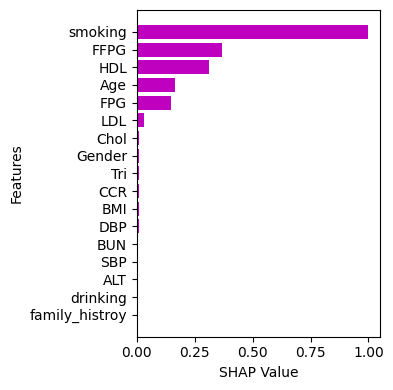

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

# 你的数据
data = {
    'Feature': ['family_histroy', 'drinking', 'ALT', 'SBP', 'BUN', 'DBP', 'BMI', 'CCR', 'Tri', 
                'Gender', 'Chol', 'LDL', 'FPG', 'Age', 'HDL', 'FFPG', 'smoking'],
    'Value': [0.000000, 0.001361, 0.003116, 0.006056, 0.006684, 0.007634, 0.008974, 
              0.009391, 0.009479, 0.010597, 0.011200, 0.031564, 0.148553, 0.166374, 
              0.312866, 0.365484, 1.000000]
}

# 创建DataFrame
df = pd.DataFrame(data)

# 按值排序
df = df.sort_values(by='Value', ascending=True)

# 获取排序后的特征标签和值
sorted_labels = df['Feature']
sorted_values = df['Value']

# 创建一个特定大小的图形
plt.figure(figsize=(4, 4))

# 绘制水平条形图
plt.barh(sorted_labels, sorted_values, color='m')

# 添加坐标轴标签
plt.xlabel('SHAP Value')
plt.ylabel('Features')

# 添加标题
# plt.title('Feature Importance', fontsize=14)

# 调整布局以适应大小
plt.tight_layout()

# 保存高分辨率图像
plt.savefig('Samplingshap_diabetes_lgb_normalized.eps', format='eps', dpi=300, bbox_inches='tight')

# 显示图表
plt.show()

In [ ]:
plt.figure(figsize=(4, 4))
# colors = plt.cm.viridis(range(len(sorted_feature_importance_df)))

# colors = plt.color_palette("c", len(shap_values_per_feature_sorted))

# Plot the sorted SHAP values for each feature vertically
bar_plot = shap_values_per_feature_normalized.plot(kind='barh', color='m')
# plt.title('SHAP Values for H1N1 Vaccine Features', fontsize=14)
plt.xlabel('SHAP Value')
plt.ylabel('Feature')

# # Annotate the bars with SHAP values
# for i, value in enumerate(shap_values_per_feature_sorted):
#     bar_plot.text(value + 0.01, i, f'{value:.4f}', ha='left', va='center', fontsize=8)

plt.tight_layout()  # Adjusts subplot parameters to give specified padding

plt.savefig('Samplingshap_diabetes_lgb_normalized.eps', format='eps', dpi=300)

plt.show()

NameError: name 'plt' is not defined

In [27]:
import time
s = time.time()
def custom_predict(x_test):
    # 使用 LightGBM 模型进行预测
    return model.predict(x_test)

kernel = shap.KernelExplainer(custom_predict,x_test)
KernelExplainer = kernel.shap_values(x_test)

Using 861 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.
100%|██████████| 861/861 [35:48<00:00,  2.50s/it]


In [28]:
shap.summary_plot(KernelExplainer, x_test, plot_type="bar", show=False)


In [29]:
e = time.time()
e-s

2148.7807109355927

In [34]:
import pandas as pd
import matplotlib.pyplot as plt


# Extract and display the SHAP values for each feature
shap_df = pd.DataFrame(KernelExplainer, columns=x_test.columns)
shap_values_per_feature = shap_df.abs().mean()  # Calculate the average absolute SHAP value per feature

# Sort SHAP values from largest to smallest
shap_values_per_feature_sorted = shap_values_per_feature.sort_values(ascending=True)
shap_values_per_feature_sorted

ALT               0.002536
family_histroy    0.002611
drinking          0.002889
SBP               0.003212
BUN               0.003431
DBP               0.003432
Tri               0.003734
BMI               0.003802
CCR               0.004193
Chol              0.004342
Gender            0.005284
LDL               0.008926
FPG               0.030031
Age               0.033020
HDL               0.058685
FFPG              0.068832
smoking           0.183195
dtype: float64

In [35]:
shap_values_per_feature_normalized = (shap_values_per_feature - shap_values_per_feature.min()) / (shap_values_per_feature.max() - shap_values_per_feature.min())
shap_values_per_feature_normalized = shap_values_per_feature_normalized.sort_values(ascending=True)
shap_values_per_feature_normalized

ALT               0.000000
family_histroy    0.000416
drinking          0.001953
SBP               0.003741
BUN               0.004957
DBP               0.004958
Tri               0.006630
BMI               0.007009
CCR               0.009173
Chol              0.009997
Gender            0.015212
LDL               0.035370
FPG               0.152191
Age               0.168738
HDL               0.310803
FFPG              0.366966
smoking           1.000000
dtype: float64

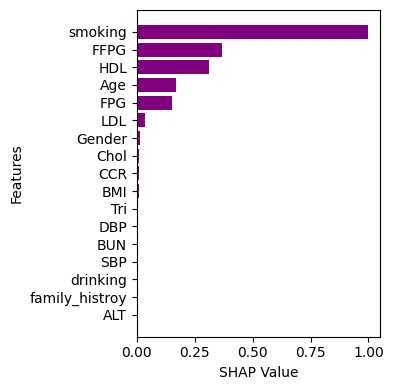

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

# 你的数据
data = {
    'Feature': ['ALT', 'family_histroy', 'drinking', 'SBP', 'BUN', 'DBP', 'Tri', 
                'BMI', 'CCR', 'Chol', 'Gender', 'LDL', 'FPG', 'Age', 'HDL', 'FFPG', 'smoking'],
    'Value': [0.000000, 0.000416, 0.001953, 0.003741, 0.004957, 0.004958, 0.006630, 
              0.007009, 0.009173, 0.009997, 0.015212, 0.035370, 0.152191, 0.168738, 
              0.310803, 0.366966, 1.000000]
}

# 创建DataFrame
df = pd.DataFrame(data)

# 按值排序
df = df.sort_values(by='Value', ascending=True)

# 获取排序后的特征标签和值
sorted_labels = df['Feature']
sorted_values = df['Value']

# 创建一个特定大小的图形
plt.figure(figsize=(4, 4))

# 绘制水平条形图
plt.barh(sorted_labels, sorted_values, color='purple')

# 添加坐标轴标签
plt.xlabel('SHAP Value')
plt.ylabel('Features')

# 添加标题
# plt.title('Feature Importance', fontsize=14)

# 调整布局以适应大小
plt.tight_layout()

# 保存高分辨率图像
plt.savefig('Kernelshap_diabetes_lgb_normalized.eps', format='eps', dpi=300, bbox_inches='tight')

# 显示图表
plt.show()

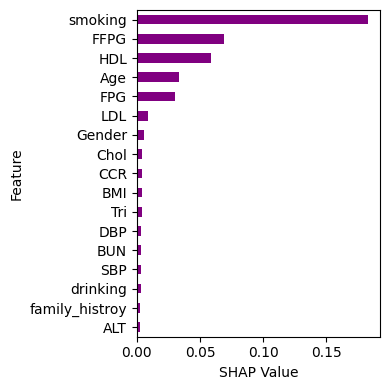

In [ ]:
plt.figure(figsize=(4, 4))
# colors = plt.cm.viridis(range(len(sorted_feature_importance_df)))

# colors = plt.color_palette("c", len(shap_values_per_feature_sorted))

# Plot the sorted SHAP values for each feature vertically
bar_plot = shap_values_per_feature_normalized.plot(kind='barh', color='purple')
# plt.title('SHAP Values for H1N1 Vaccine Features', fontsize=14)
plt.xlabel('SHAP Value')
plt.ylabel('Feature')

# # Annotate the bars with SHAP values
# for i, value in enumerate(shap_values_per_feature_sorted):
#     bar_plot.text(value + 0.01, i, f'{value:.4f}', ha='left', va='center', fontsize=8)

plt.tight_layout()  # Adjusts subplot parameters to give specified padding

plt.savefig('Kernelshap_diabetes_lgb_normalized.eps', format='eps', dpi=300)

plt.show()

In [7]:
# Get feature importances
import time
s = time.time()

feature_importance = model.feature_importances_

# Create a DataFrame to display feature names and their corresponding importance values
feature_importance_df = pd.DataFrame({'Feature': x_train.columns, 'Importance': feature_importance})

# Sort the features based on their importance values
sorted_feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

# Display the sorted feature importances
print(sorted_feature_importance_df)


           Feature  Importance
13            FFPG         301
5              FPG         285
8              HDL         279
0              Age         259
2              BMI         238
9              LDL         223
12             CCR         193
11             BUN         190
10             ALT         189
6             Chol         177
7              Tri         173
4              DBP         146
3              SBP         146
14         smoking         113
16  family_histroy          33
1           Gender          30
15        drinking          25


In [8]:
e = time.time()
e-s

0.3160359859466553

In [38]:
# 最小-最大归一化到 [0, 1] 之间
sorted_feature_importance_df['Normalized Importance'] = (
    sorted_feature_importance_df['Importance'] - sorted_feature_importance_df['Importance'].min()
) / (
    sorted_feature_importance_df['Importance'].max() - sorted_feature_importance_df['Importance'].min()
)

# 打印归一化后的特征重要性
sorted_feature_importance_df

,Feature,Importance,Normalized Importance
13,FFPG,301,1.000000
5,FPG,285,0.942029
8,HDL,279,0.920290
0,Age,259,0.847826
2,BMI,238,0.771739
9,LDL,223,0.717391
12,CCR,193,0.608696
11,BUN,190,0.597826
10,ALT,189,0.594203
6,Chol,177,0.550725


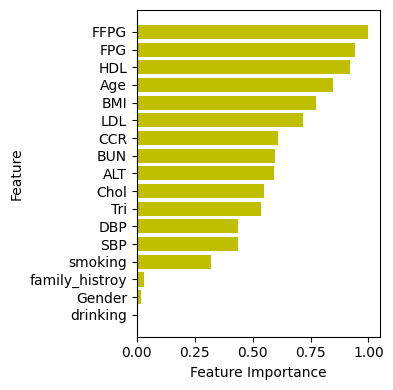

In [39]:
plt.figure(figsize=(4, 4))  # 改变图形大小，使其适应竖向显示
plt.barh(sorted_feature_importance_df['Feature'], sorted_feature_importance_df['Normalized Importance'], color='y')
plt.ylabel('Feature')
plt.xlabel('Feature Importance')
# plt.title('Feature Importance')
plt.gca().invert_yaxis()  # 反转y轴，使重要性最高的特征位于顶部
plt.tight_layout()

# 保存图像为300 dpi的EPS格式
plt.savefig('feature_importance_diabetes_lgb_normalized.eps', format='eps', dpi=300)

# 显示图像
plt.show()

In [9]:
import time
s = time.time()

from lime import lime_tabular
from lime.lime_tabular import LimeTabularExplainer

explainer = LimeTabularExplainer(x_test.values,
                                 feature_names=x_train.columns.tolist(),
                                 mode='classification')
sample_idx = 2  # Choose an index of the test set
exp = explainer.explain_instance(x_test.iloc[sample_idx].values, model.predict_proba, num_features=len(x_test.columns))

In [10]:
# Extract feature values and their weights
feature_values = exp.as_list()
feature_values

[('smoking <= 3.00', -0.8415440652272606),
 ('5.25 < FFPG <= 5.81', -0.08510623457344713),
 ('Age <= 35.00', -0.08165363983252985),
 ('1.35 < HDL <= 1.60', -0.07331186668933586),
 ('family_histroy <= 0.00', -0.056327872218314555),
 ('ALT <= 14.00', -0.021050801821359356),
 ('DBP <= 69.00', 0.020499214563493934),
 ('CCR <= 59.80', 0.017732338412588918),
 ('BUN <= 3.90', -0.013503382656301886),
 ('BMI <= 21.50', -0.013249424387354167),
 ('drinking <= 3.00', -0.013104996068342402),
 ('0.84 < Tri <= 1.30', 0.010549786203699575),
 ('2.82 < LDL <= 3.35', 0.009756027074418786),
 ('5.10 < FPG <= 5.63', -0.0036144024144370577),
 ('SBP <= 110.00', 0.0031945413878753603),
 ('4.80 < Chol <= 5.44', 0.0025693712125554264),
 ('1.00 < Gender <= 2.00', -0.0017079317516126649)]

In [11]:
e = time.time()
e-s

0.5532510280609131

In [71]:
feature_values = [('smoking', 0.8399809699790036),
 ('FFPG', 0.26720592278698885),
 ('FPG', 0.10382918106276844),
 ('Age', -0.054227135076094495),
 ('family_histroy', -0.038512009171133905),
 ('Gender', 0.02409953689375437),
 ('drinking', 0.02206355308541353),
 ('HDL', -0.0163067967661488),
 ('Chol', 0.015773575652656913),
 ('CCR', 0.013744867373255447),
 ('SBP', 0.012157329894304313),
 ('BMI', -0.011716925016818154),
 ('Tri', 0.007866503320020252),
 ('LDL', 0.006877144103068048),
 ('BUN', -0.006356222040294319),
 ('ALT', 0.004058492770100404),
 ('DBP', -0.00020605987376370063)]


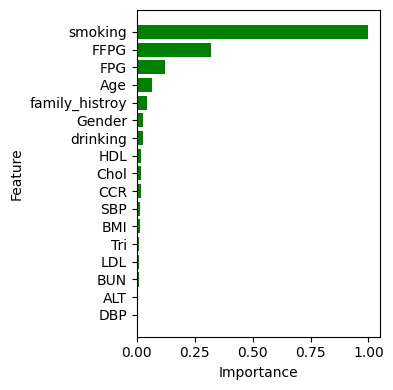

In [78]:
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import numpy as np

feature_values = [('smoking', 0.8399809699790036),
 ('FFPG', 0.26720592278698885),
 ('FPG', 0.10382918106276844),
 ('Age', -0.054227135076094495),
 ('family_histroy', -0.038512009171133905),
 ('Gender', 0.02409953689375437),
 ('drinking', 0.02206355308541353),
 ('HDL', -0.0163067967661488),
 ('Chol', 0.015773575652656913),
 ('CCR', 0.013744867373255447),
 ('SBP', 0.012157329894304313),
 ('BMI', -0.011716925016818154),
 ('Tri', 0.007866503320020252),
 ('LDL', 0.006877144103068048),
 ('BUN', -0.006356222040294319),
 ('ALT', 0.004058492770100404),
 ('DBP', -0.00020605987376370063)]

feature_values_abs = [(name, abs(value)) for name, value in feature_values]
feature_values_abs_sorted = sorted(feature_values_abs, key=lambda x: x[1], reverse=False)


features, values = zip(*feature_values_abs_sorted)
# 将权重转换为numpy数组
values = np.array(values).reshape(-1, 1)

# 使用MinMaxScaler进行归一化
scaler = MinMaxScaler()
normalized_values = scaler.fit_transform(values).flatten()

# 绘制条形图
plt.figure(figsize=(4, 4))

# 使用Matplotlib的barh()函数绘制条形图
plt.barh(features, normalized_values, color='g')

plt.xlabel('Importance')  # 修改x轴标签
plt.ylabel('Feature')

# 使用tight_layout来调整图表以适应指定的图形大小
plt.tight_layout()

# 保存图像，确保DPI设置为300，并包括标签和边距
plt.savefig('Lime_diabetes_lgb_normalized.eps', format='eps', dpi=300, bbox_inches='tight')

plt.show()



In [12]:
import time
s = time.time()

from sklearn.inspection import permutation_importance
import numpy as np
result = permutation_importance(model, x_test, y_test, n_repeats=1, random_state=42, scoring='neg_mean_squared_error')

# 打印特征重要性
feature_names = X.columns.tolist()
importances = result.importances_mean
std = result.importances_std
indices = np.argsort(importances)[::-1]

print("Feature ranking:")
for f in range(x_test.shape[1]):
    print(f"{f + 1}. feature {feature_names[indices[f]]} ({importances[indices[f]]:.6f})")

Feature ranking:
1. feature smoking (0.164925)
2. feature HDL (0.036005)
3. feature FFPG (0.025552)
4. feature FPG (0.012776)
5. feature LDL (0.003484)
6. feature Age (0.003484)
7. feature drinking (0.002323)
8. feature BMI (0.001161)
9. feature family_histroy (0.001161)
10. feature Tri (0.000000)
11. feature CCR (0.000000)
12. feature DBP (0.000000)
13. feature Gender (0.000000)
14. feature BUN (-0.001161)
15. feature Chol (-0.001161)
16. feature SBP (-0.001161)
17. feature ALT (-0.002323)


In [13]:
e = time.time()
e-s

0.2347581386566162

In [80]:
# 归一化处理
min_importance = np.min(importances)
max_importance = np.max(importances)
normalized_importances = (importances - min_importance) / (max_importance - min_importance)

# 按归一化后的重要性排序
indices = np.argsort(normalized_importances)[::-1]

# 打印归一化后的特征重要性
print("Feature ranking (normalized importance):")
for f in range(x_test.shape[1]):
    print(f"{f + 1}. feature {feature_names[indices[f]]} ({normalized_importances[indices[f]]:.6f})")

Feature ranking (normalized importance):
1. feature smoking (1.000000)
2. feature HDL (0.229167)
3. feature FFPG (0.166667)
4. feature FPG (0.090278)
5. feature LDL (0.034722)
6. feature Age (0.034722)
7. feature drinking (0.027778)
8. feature BMI (0.020833)
9. feature family_histroy (0.020833)
10. feature Tri (0.013889)
11. feature CCR (0.013889)
12. feature DBP (0.013889)
13. feature Gender (0.013889)
14. feature BUN (0.006944)
15. feature Chol (0.006944)
16. feature SBP (0.006944)
17. feature ALT (0.000000)


In [81]:
# 创建一个数据框来存储特征及其重要性
feature_importance_df = pd.DataFrame({
    'Feature': [feature_names[i] for i in indices],
    'Importance': normalized_importances[indices],
    'Std': std[indices]
})

# 按重要性排序
sorted_feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=True)

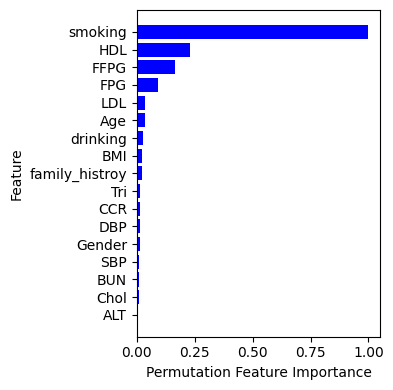

In [83]:
# 画图
plt.figure(figsize=(4, 4))  # 改变图形大小，使其适应竖向显示
plt.barh(sorted_feature_importance_df['Feature'], sorted_feature_importance_df['Importance'], color='b')
plt.ylabel('Feature')
plt.xlabel('Permutation Feature Importance')
# plt.gca().invert_yaxis()  # 反转y轴，使重要性最高的特征位于顶部
plt.tight_layout()

# 保存图像为300 dpi的EPS格式
plt.savefig('Permutation_importance_diabetes_lgb_normalized.eps', format='eps', dpi=300)

# 显示图像
plt.show()